# 10E — Final submission builder

## Same Stopwatch. Different Movement.
### What 10 Hz Combine Tracking Reveals About NFL Prospects — and How Scouts Can Use It

**This notebook computes nothing new.** It assembles the submission from executed artifacts:

1. the final figure set (10 figures; PNG + SVG + PDF), reusing the Milestone 09 figure functions where they exist;
2. the five authored documents of `reports/milestone10/` — their `‹M10:…›` tokens are filled from the 10B stories and the 10C movement gap (the authored text is kept under `templates/` and re-rendered on every run);
3. a cross-check of every Milestone 09 number typed in those documents against the mart (reported, never edited silently);
4. result tables, the figure index and the reproducibility record.

**Prerequisites.** 09E, 10A, 10B, 10C (10D optional), same `RUN_MODE`. **Writes.** `reports/figures/advanced_movement/product_v1/AM10E_*`, `reports/milestone10/{*.md, tables/, FIGURE_INDEX.md, REPRODUCIBILITY.md}`.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
RENDER_DOCUMENTS = True       # fill the ‹M10:…› tokens of the authored documents in place (templates kept under reports/milestone10/templates)

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import final_figures as ff
from nflbdb.research.advanced_movement import intelligence_figures as ifg
from nflbdb.research.advanced_movement import milestone09_artifacts as m9
from nflbdb.research.advanced_movement import milestone10_validation as v10
from nflbdb.research.advanced_movement import movement_matching as mm
from nflbdb.research.advanced_movement import product_kit as pk
from nflbdb.research.advanced_movement import scouting_interpretation as sin
from nflbdb.research.advanced_movement import submission_builder as sb
from nflbdb.research.advanced_movement.artifacts import MissingArtifactError, ProductStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = ProductStore(cfg, controls)
MART = m9.mart_path(store)
m9.assert_valid(m9.validate_mart(MART))
T, EVID, MANIFEST = m9.load_mart(MART)
OV = MANIFEST['overview']
REPORTS = store.reports_dir
S10B = store.read_json('signature_stories', '10b_signature_football_stories.ipynb')
S10C = store.read_json('movement_gap', '10c_nfl_movement_gap.ipynb')
STORIES, G, GS, FOCUS = S10B['stories'], S10C['matrix'], S10C['summary'], S10C['focus']
try:
    S10D = store.read_json('decision_demonstration', '10d_decision_simulator_demonstration.ipynb')
except MissingArtifactError:
    S10D = {}
C = T['combine_attempt_curves']

def curves(i):
    return [(g['dist_yd'].to_numpy().astype(float), g['speed'].to_numpy().astype(float)) for g in
            C.filter(pl.col('nfl_id') == i).sort('attempt_order', 'frame').partition_by(['attempt_order'], as_dict=True, maintain_order=True).values()]

def band(pos):
    B = T['position_curve_bands'].filter(pl.col('position_group') == pos).sort('dist_yd')
    return {'grid': B['dist_yd'].to_numpy(), 'q10': B['q10'].to_numpy(), 'q50': B['q50'].to_numpy(), 'q90': B['q90'].to_numpy(), 'n': int(B['n_runs'][0])} if B.height else None

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
focus_pos = FOCUS['position_group'] if FOCUS else 'none'
has_10d = 'present' if S10D else 'absent'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · mart built {MANIFEST["built_at"]} · stories {sorted(STORIES)} · gap focus {focus_pos} · 10D {has_10d}'))

**Run mode: `full`** (FULL) · mart built 2026-10-14T13:13:05Z · stories ['gap', 'same_forty', 'wr'] · gap focus WR · 10D present

## 1 · The final figure set

The hero pair is the Story 2 pair (same official forty); if 10B found none, the top-ranked twin pair.

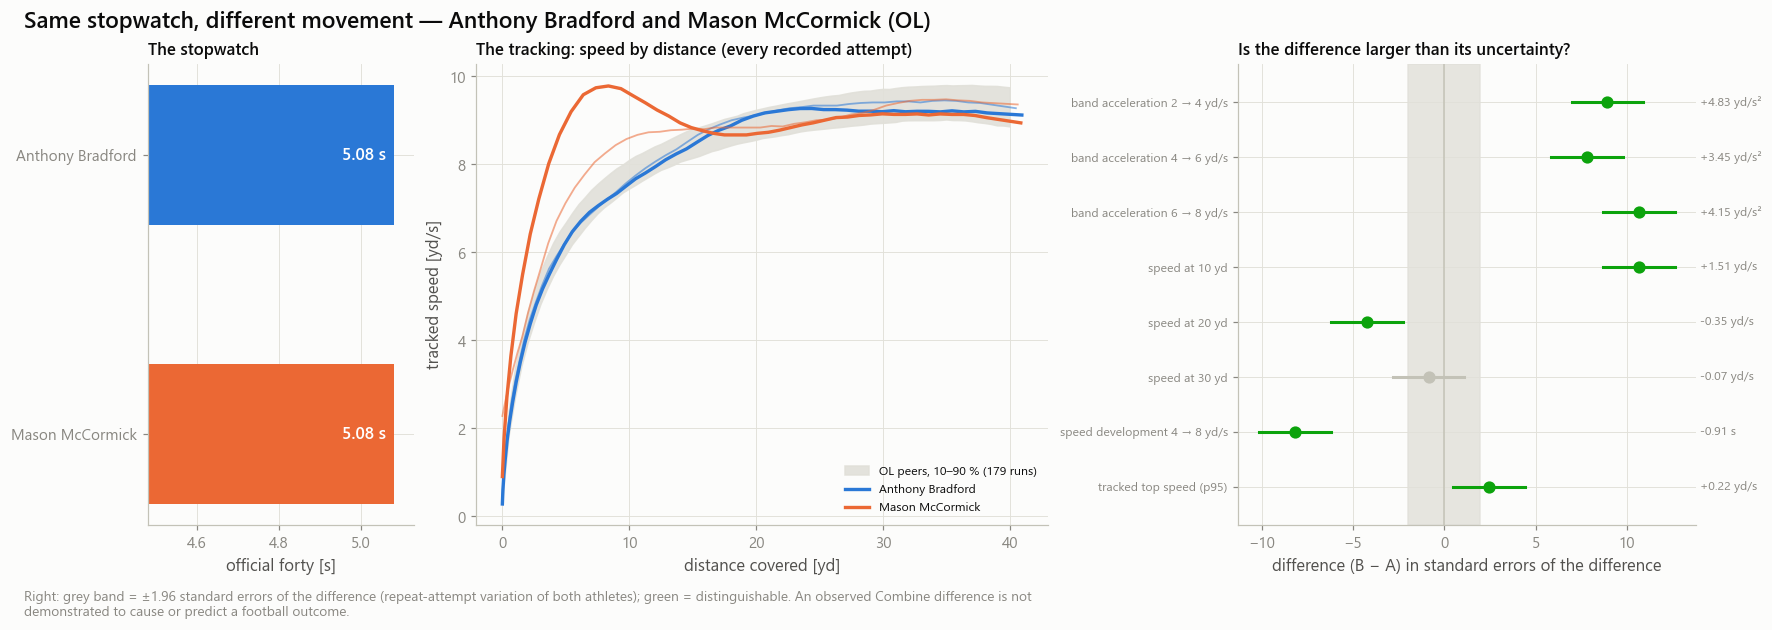

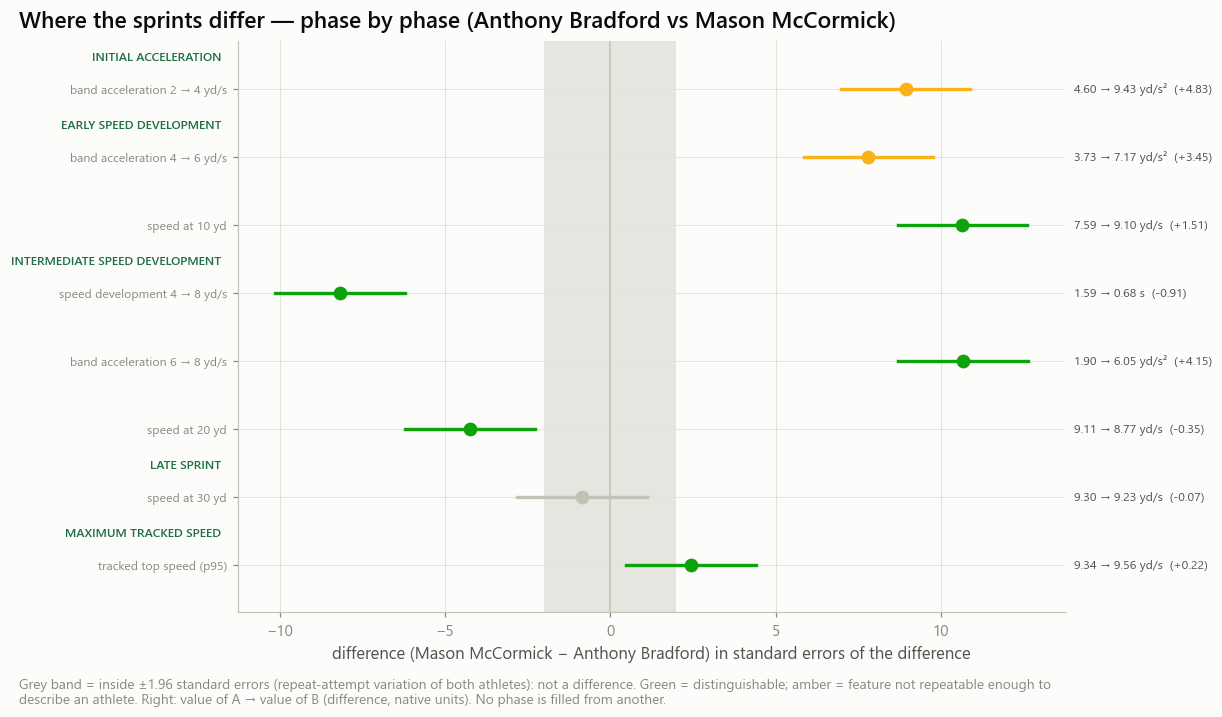

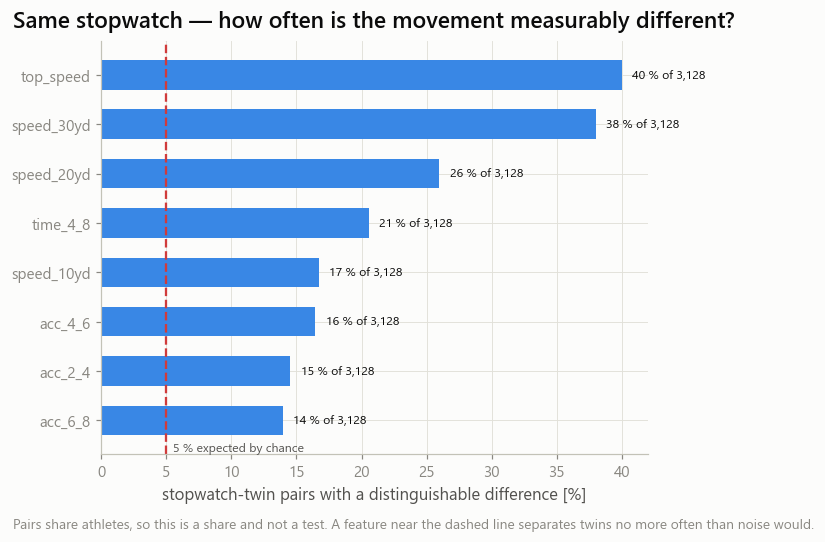

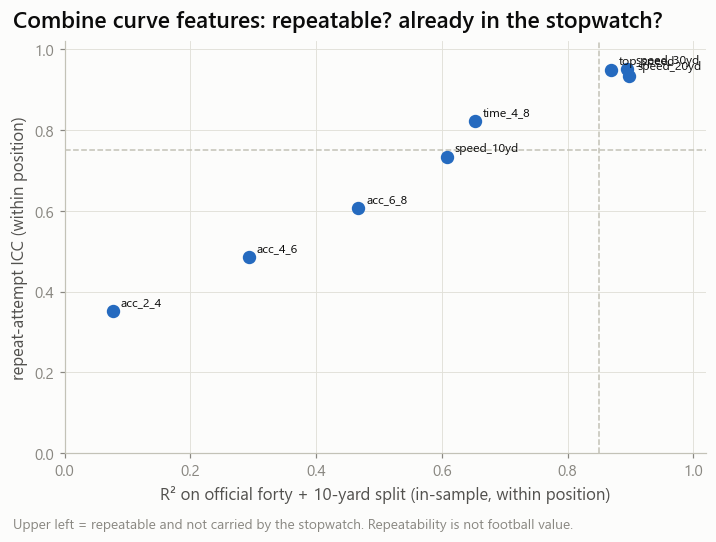

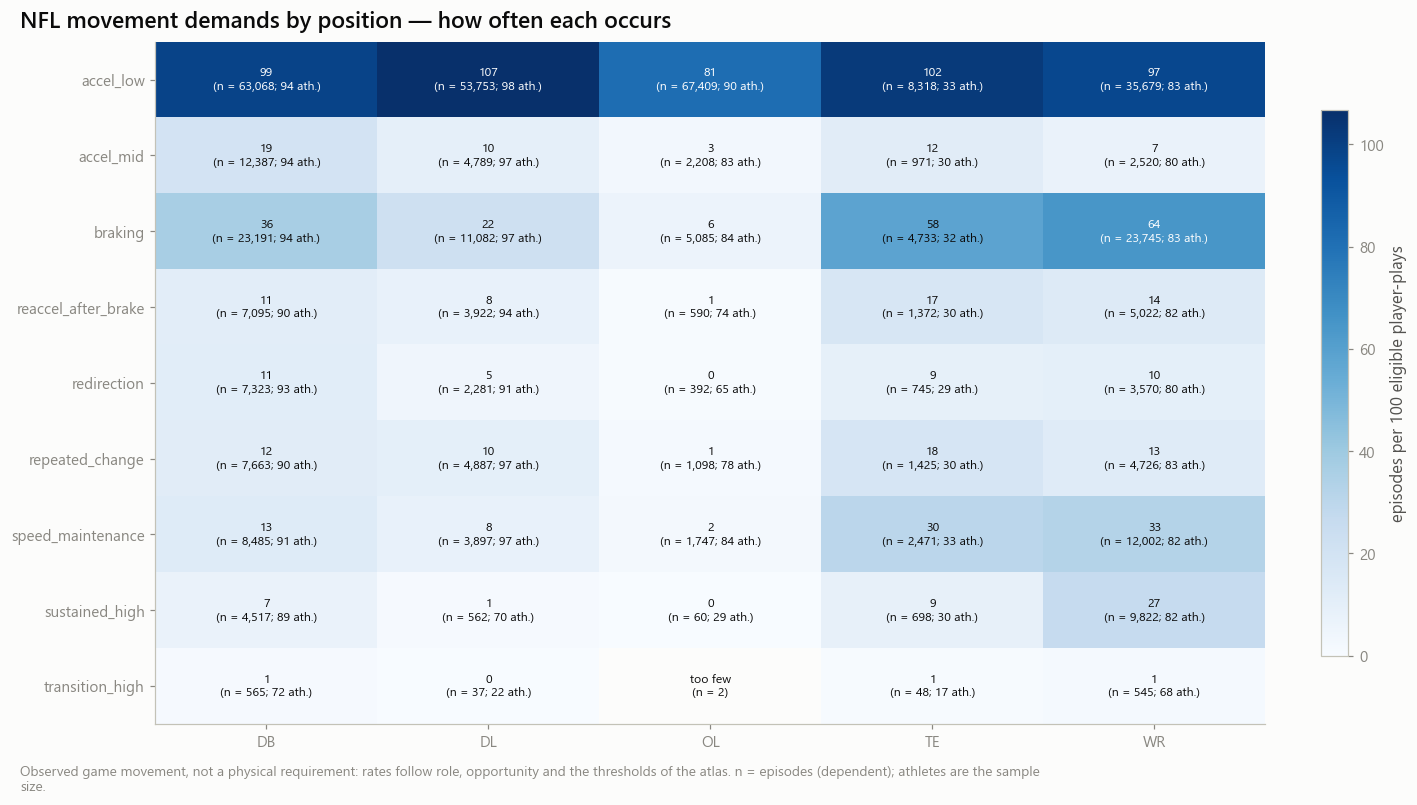

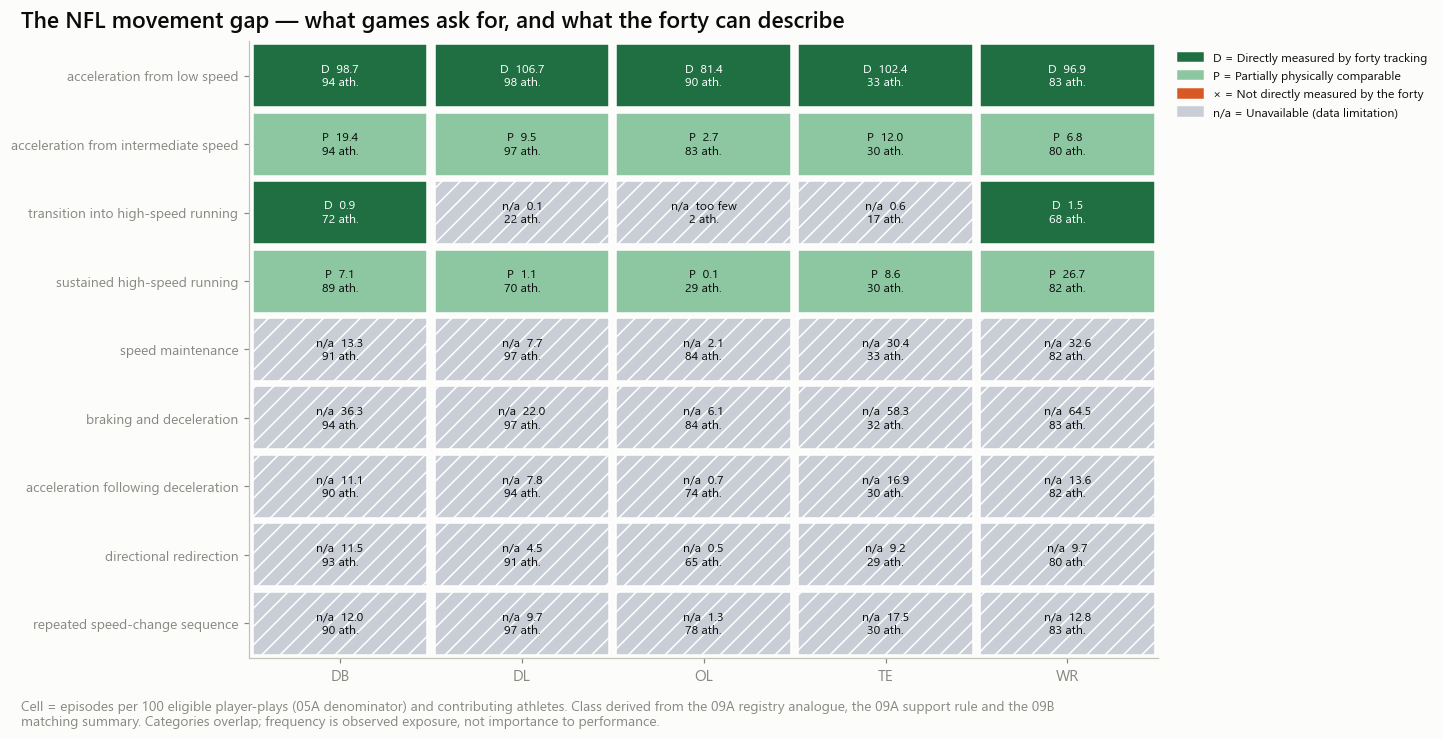

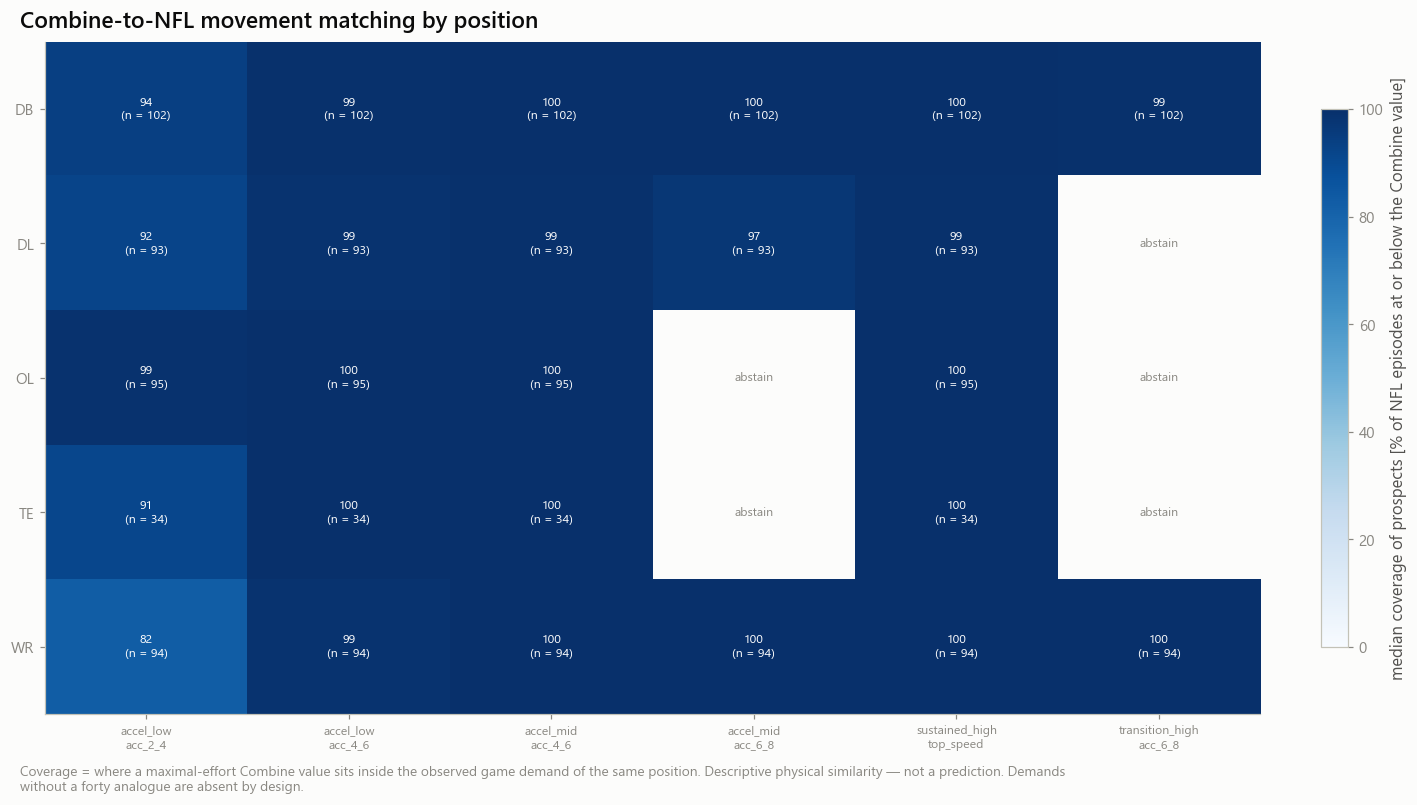

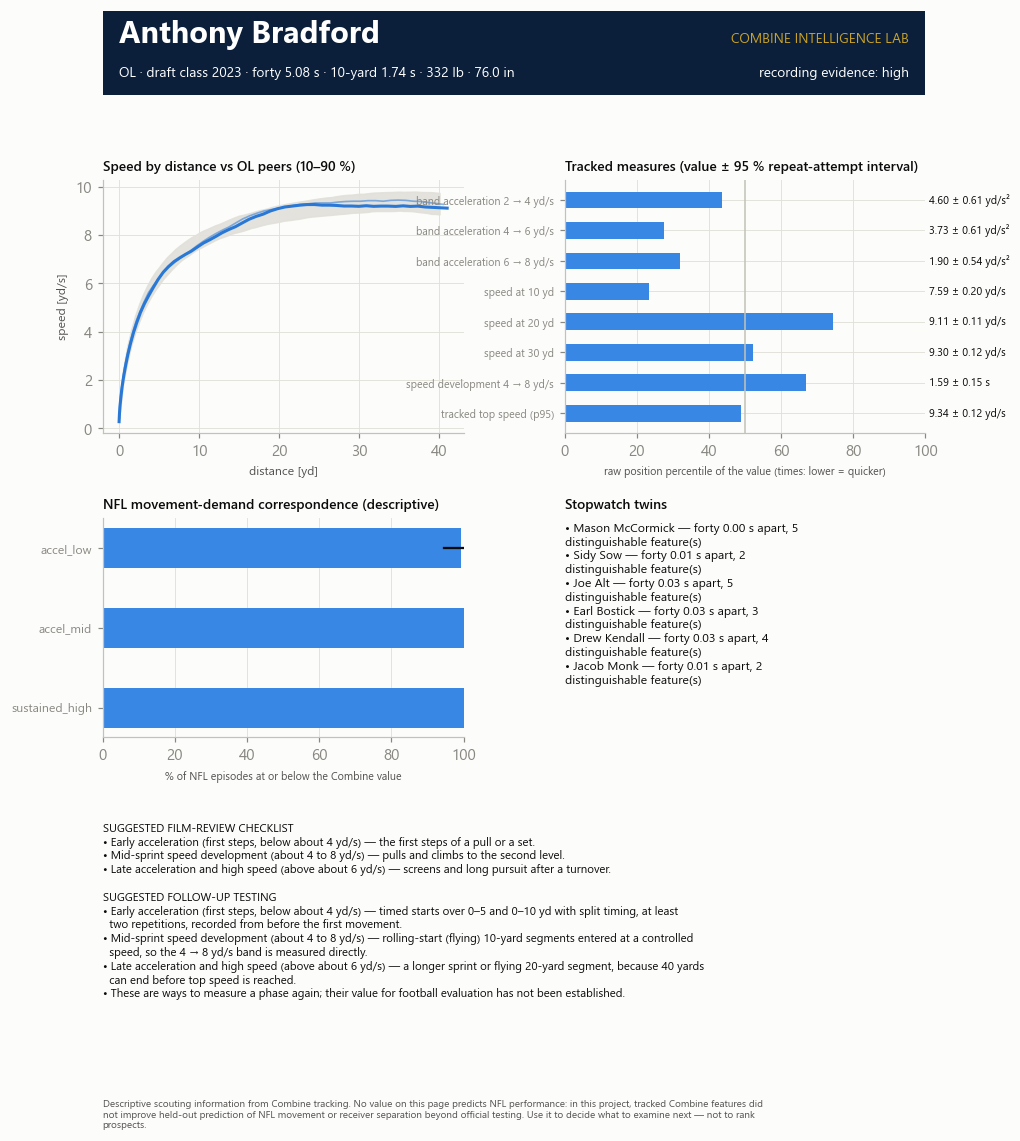

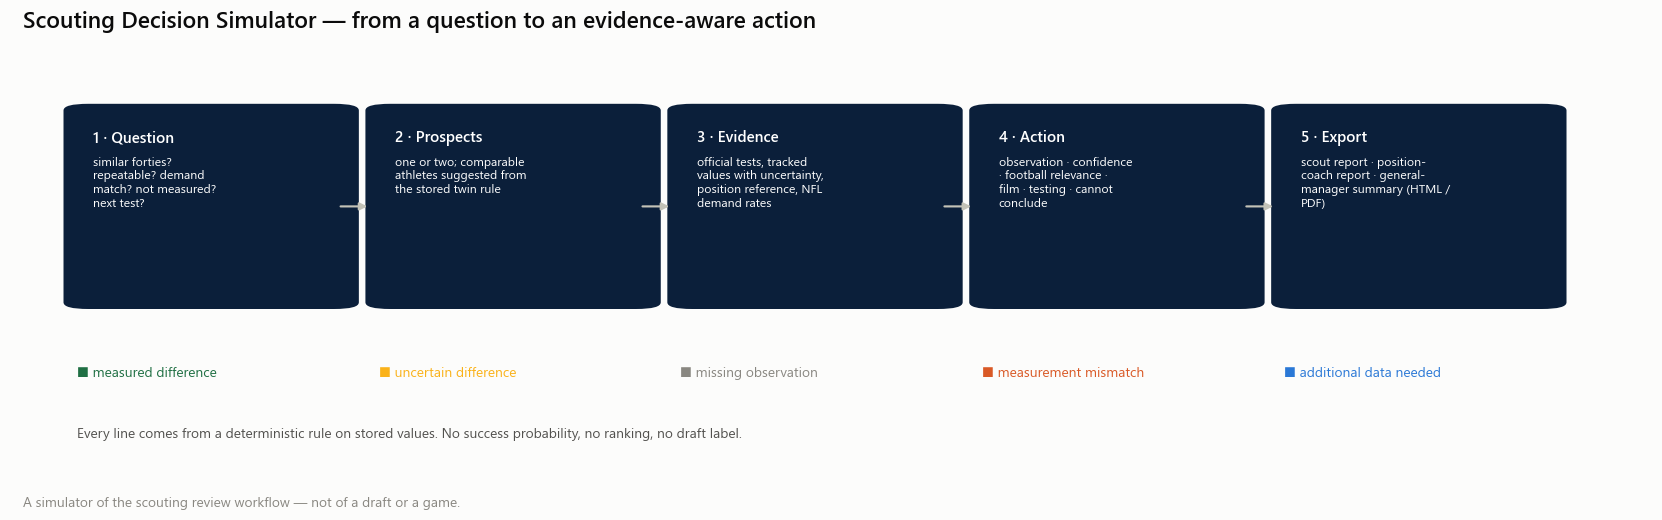

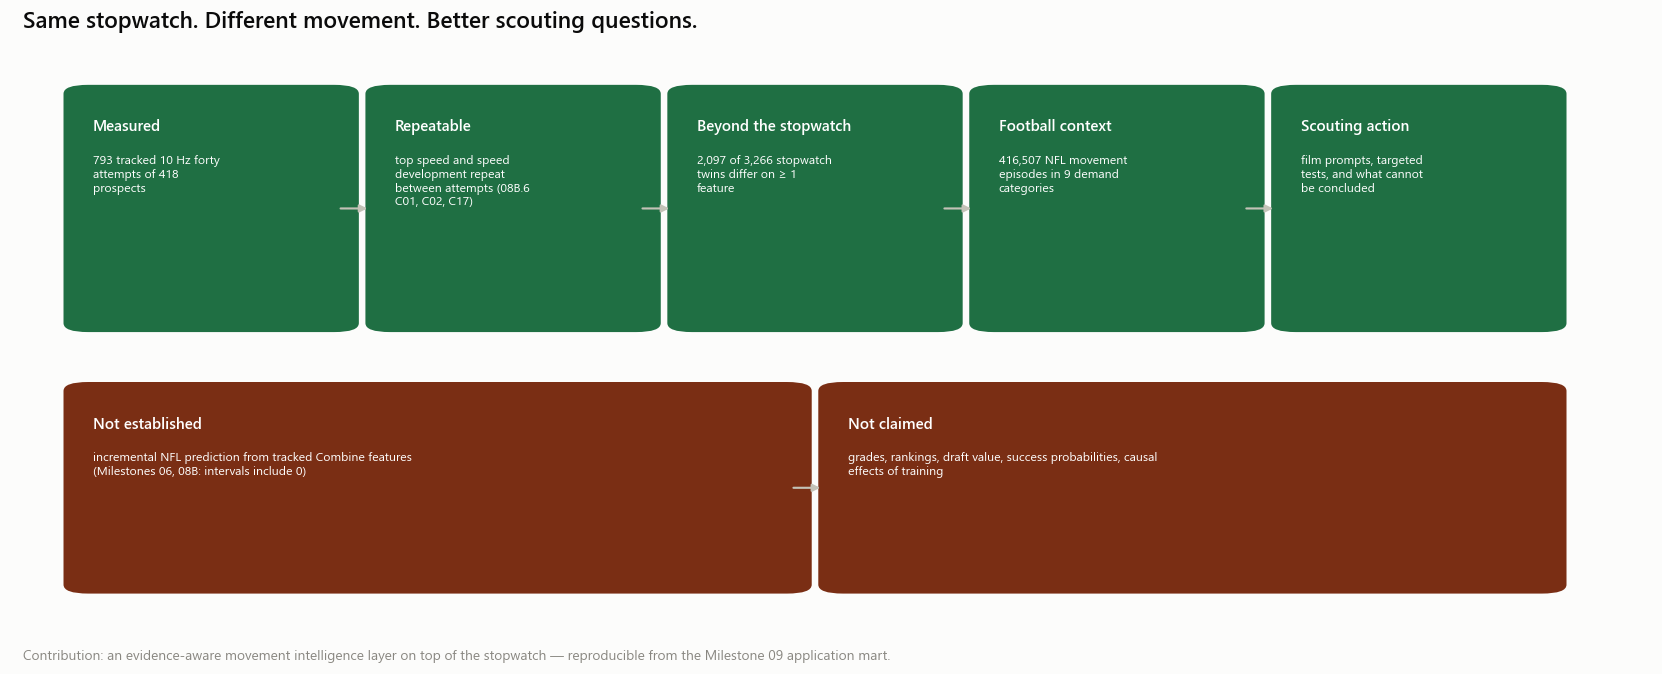

n,figure,name,path,has_png,has_svg,has_pdf
str,str,str,str,bool,bool,bool
"""01""","""Hero stopwatch-twin sprint com…","""AM10E_01_hero_stopwatch_twins""","""reports/figures/advanced_movem…",true,true,true
"""02""","""Speed-development decompositio…","""AM10E_02_phase_decomposition""","""reports/figures/advanced_movem…",true,true,true
"""03""","""Matched-pair distinguishabilit…","""AM10E_03_twin_distinguishabili…","""reports/figures/advanced_movem…",true,true,true
"""04""","""Reliability versus redundancy""","""AM10E_04_reliability_vs_redund…","""reports/figures/advanced_movem…",true,true,true
"""05""","""NFL movement demands by positi…","""AM10E_05_nfl_demands_by_positi…","""reports/figures/advanced_movem…",true,true,true
"""06""","""NFL Movement Gap matrix""","""AM10E_06_movement_gap_matrix""","""reports/figures/advanced_movem…",true,true,true
"""07""","""Combine-to-NFL physical corres…","""AM10E_07_physical_corresponden…","""reports/figures/advanced_movem…",true,true,true
"""08""","""One-player scouting profile""","""AM10E_08_scouting_profile""","""reports/figures/advanced_movem…",true,true,true
"""09""","""Scout decision workflow""","""AM10E_09_decision_workflow""","""reports/figures/advanced_movem…",true,true,true


In [3]:
TW = T['stopwatch_twins']
hero_id = STORIES['same_forty']['provenance']['pair_id'] if 'same_forty' in STORIES else TW.sort('max_abs_z', descending=True, nulls_last=True)['pair_id'][0]
HERO = TW.filter(pl.col('pair_id') == hero_id).row(0, named=True)
HD = T['twin_differences'].filter(pl.col('pair_id') == hero_id).sort('feature').to_dicts()
names = (HERO['name_a'], HERO['name_b'])
N = {k: name for k, _, name in sb.FINAL_FIGURES}
MC = mm.MatchingConfig()
show = lambda fig, k, src, n: store.show(fig, N[k], {}, publication=True, source=src, n=n)
show(ifg.fig_twin_story(HERO, {names[0]: curves(HERO['nfl_id_a']), names[1]: curves(HERO['nfl_id_b'])}, band(HERO['position_group']), HD), '01',
     'stopwatch_twins + twin_differences + combine_attempt_curves', 'two athletes')
show(ff.fig_phase_decomposition(pk.phase_decomposition(HD), names), '02', 'twin_differences', 'two athletes')
show(ifg.fig_twin_summary(T['twin_summary']), '03', 'twin_summary', f'{OV["n_twin_pairs"]:,} pairs (not independent)')
show(ifg.fig_feature_evidence(T['feature_evidence'], MC.icc_reference, MC.redundancy_reference), '04', 'feature_evidence (09B / 08B.4)', 'tracked athletes')
show(ifg.fig_demand_frequency(T['nfl_movement_demands']), '05', 'nfl_movement_demands', f'{OV["n_nfl_episodes"]:,} episodes')
show(ff.fig_movement_gap(G), '06', '10C movement gap', f'{OV["n_nfl_episodes"]:,} episodes')
show(ifg.fig_similarity_heatmap(T['movement_matching_summary']), '07', 'movement_matching_summary', 'prospects per cell annotated')
i = HERO['nfl_id_a']
prof = T['prospect_profiles'].filter(pl.col('nfl_id') == i).row(0, named=True)
mine = [{**r, 'other_name': r['name_b'] if r['nfl_id_a'] == i else r['name_a'], 'd_forty': r['d_forty'] if r['nfl_id_a'] == i else -r['d_forty']}
        for r in TW.filter((pl.col('nfl_id_a') == i) | (pl.col('nfl_id_b') == i)).sort('max_abs_z', descending=True, nulls_last=True).iter_rows(named=True)]
met = T['prospect_metrics'].filter(pl.col('nfl_id') == i).sort('feature').to_dicts()
mat = T['movement_similarity_matrix'].filter(pl.col('nfl_id') == i).to_dicts()
show(ifg.fig_intelligence_card(prof, met, mine, mat, curves(i), band(prof['position_group']), sin.prospect_report(prof, met, mine, mat, T['feature_evidence'].to_dicts())),
     '08', 'prospect profile + metrics + twins + matching', 'one athlete')
show(ff.fig_decision_workflow(), '09', 'decision_simulator (diagram)', '—')
show(ff.fig_contribution(OV), '10', 'mart overview', 'see figure')
FIG_INDEX = sb.figure_index(store.figures_dir, cfg.paths.rel)
display(FIG_INDEX)

## 2 · Fill the submission documents from executed artifacts

In [4]:
VALUES = sb.token_values(T, MANIFEST, STORIES, GS, FOCUS, G)
AUDIT = sb.render_documents(REPORTS, VALUES, write=RENDER_DOCUMENTS and controls.save_tables)
display(AUDIT)
if (AUDIT['missing'] != '').any():
    print('Unfilled tokens remain visible in the documents (listed above). They are values no executed artifact provides; send the list back.')

document,tokens,filled,missing,written
str,i64,i64,str,bool
"""NFL_BDB_2027_FINAL_SUBMISSION.…",17,17,"""""",true
"""EXECUTIVE_SCOUTING_BRIEF.md""",4,4,"""""",true
"""TECHNICAL_APPENDIX.md""",6,6,"""""",true
"""SUBMISSION_WALKTHROUGH.md""",5,5,"""""",true
"""DEMO_VIDEO_STORYBOARD.md""",3,3,"""""",true


## 3 · Cross-check the typed Milestone 09 numbers against the mart

The documents quote a few executed Milestone 09 counts directly (from `reports/milestone09/EXECUTED_NUMBERS.md`). Each is recomputed from the mart here. `False` = the document must be corrected by hand; nothing is rewritten automatically.

In [5]:
STATIC = sb.check_static_numbers(REPORTS, OV, T, names=('NFL_BDB_2027_FINAL_SUBMISSION.md',))
display(STATIC)
bad = STATIC.filter(~pl.col('present_in_document'))
print('All typed anchors of the main submission match the mart.' if bad.is_empty() else f'{bad.height} anchor(s) differ from the mart — correct them by hand.')

document,anchor,mart_value,present_in_document
str,str,str,bool
"""NFL_BDB_2027_FINAL_SUBMISSION.…","""prospects""","""510""",true
"""NFL_BDB_2027_FINAL_SUBMISSION.…","""tracked prospects""","""418""",true
"""NFL_BDB_2027_FINAL_SUBMISSION.…","""tracked attempts""","""793""",true
"""NFL_BDB_2027_FINAL_SUBMISSION.…","""NFL episodes""","""416,507""",true
"""NFL_BDB_2027_FINAL_SUBMISSION.…","""twin pairs""","""3,266""",true
"""NFL_BDB_2027_FINAL_SUBMISSION.…","""distinguishable pairs""","""2,097""",true
"""NFL_BDB_2027_FINAL_SUBMISSION.…","""case studies""","""23""",true
"""NFL_BDB_2027_FINAL_SUBMISSION.…","""hero forty""","""5.08""",true


All typed anchors of the main submission match the mart.


## 4 · Result tables, figure index, reproducibility record

In [6]:
tdir = REPORTS / 'tables'
logic = v10.run_all()
if controls.save_tables:
    tdir.mkdir(parents=True, exist_ok=True)
    T['twin_summary'].filter(pl.col('position_group') == 'ALL').write_csv(tdir / 'stopwatch_twin_distinguishability.csv')
    T['nfl_movement_demands'].write_csv(tdir / 'nfl_movement_demands_by_position.csv')
    T['feature_evidence'].write_csv(tdir / 'combine_feature_evidence.csv')
    pl.DataFrame(GS).write_csv(tdir / 'movement_gap_summary.csv')
    pl.DataFrame([{k: v for k, v in c.items() if k in ('claim_id', 'claim', 'value', 'n', 'evidence_level', 'limitation')} for c in EVID.get('evidence_claims_08b6', [])]
                 ).write_csv(tdir / 'evidence_claims_08b6.csv')
    fig_md = ['# Final figure index', '', f'_Generated {utc_now()} · run mode {controls.run_mode}._', '', '| # | Figure | File | PNG | SVG | PDF |', '|---|---|---|---|---|---|']
    fig_md += [f"| {r['n']} | {r['figure']} | `{r['path']}` | {'✓' if r['has_png'] else '—'} | {'✓' if r['has_svg'] else '—'} | {'✓' if r['has_pdf'] else '—'} |" for r in FIG_INDEX.iter_rows(named=True)]
    (REPORTS / 'FIGURE_INDEX.md').write_text('\n'.join(fig_md) + '\n', encoding='utf-8')
    mf = MANIFEST['files']
    rep = ['# Reproducibility record — Milestone 10', '', f'_Generated {utc_now()} · run mode {controls.run_mode} · seed {controls.seed}._', '',
           '## Order of execution (Jupyter, same RUN_MODE)', '', '1. Milestones 00–08B (executed; frozen conclusions in `docs/RESEARCH_DECISIONS.md`).',
           '2. `09a` → `09g` (application mart `' + cfg.paths.rel(MART) + '`).', '3. `10a_application_readiness` → `10b_signature_football_stories` → '
           '`10c_nfl_movement_gap` → `10d_decision_simulator_demonstration` → `10e_final_submission_builder`.',
           '4. Optional, from a terminal: `cd apps/combine_intelligence_lab` then `streamlit run app.py`; walk `reports/milestone10/APP_BROWSER_CHECKLIST.md`.', '',
           '## Inputs', '', f"- Mart version {MANIFEST['mart_version']}, built {MANIFEST['built_at']} ({len(mf)} files; fingerprints in `mart_manifest.json`).",
           f"- 10B finished {S10B.get('finished_at')} · 10C finished {S10C.get('finished_at')} · 10D {'finished ' + str(S10D.get('finished_at')) if S10D else 'not run'}.", '',
           '## Engine versions', '', f'- product_kit {pk.VERSION} · submission_builder {sb.VERSION} · scouting_interpretation {sin.VERSION}', '',
           '## Checks at build time', '', f"- Milestone 10 synthetic checks: {int((logic['status'] == 'PASS').sum())} / {logic.height} PASS",
           f"- Document tokens: {int(AUDIT['filled'].sum())} filled / {int(AUDIT['tokens'].sum())} declared",
           f"- Typed Milestone 09 anchors matching the mart: {int(STATIC['present_in_document'].sum())} / {STATIC.height}", '',
           '## What is NOT reproduced here', '', '- No warehouse rebuild, no model training, no new statistical test: Milestone 10 reads persisted artifacts only.']
    (REPORTS / 'REPRODUCIBILITY.md').write_text('\n'.join(rep) + '\n', encoding='utf-8')
    store.write_json('submission_manifest', {'finished_at': utc_now(), 'documents': AUDIT.to_dicts(), 'figures': FIG_INDEX.to_dicts(), 'static_check': STATIC.to_dicts(),
                                             'mart_built_at': MANIFEST['built_at'], 'hero_pair': hero_id})
display(logic.select('check', 'status'))
print('Send back: the token audit (section 2), any False row of section 3, and FIGURE_INDEX.md. Then review NFL_BDB_2027_FINAL_SUBMISSION.md end to end.')

check,status
str,str
"""phase_decomposition_never_inve…","""PASS"""
"""replay_never_extrapolates""","""PASS"""
"""evidence_labels_and_stability""","""PASS"""
"""coverage_classes_follow_the_re…","""PASS"""
"""gap_summary_and_focus_rule""","""PASS"""
…,…
"""simulator_sections_and_categor…","""PASS"""
"""simulator_audiences_and_wordin…","""PASS"""
"""wr_selection_rules""","""PASS"""


Send back: the token audit (section 2), any False row of section 3, and FIGURE_INDEX.md. Then review NFL_BDB_2027_FINAL_SUBMISSION.md end to end.
